# Reuters: 46-class newswire topic classification

Experiments with a plain fully connected (dense) network, following the classic Keras examples. Code is unchanged from the original run; only warnings (which contained local file paths) were removed from the saved outputs.

**Experiments:** baseline → ReLU vs. Tanh → MSE vs. cross-entropy loss → number of input words (where applicable) → number of hidden layers → number of neurons.

Results of the number-of-words / layers / neurons experiments are shown as plots only (no numeric summary was printed). Runs are not seeded, so the same configuration gives slightly different numbers in different cells.

**Setup:** 10,000 most frequent words, multi-hot input, Dense(64)-Dense(64)-softmax(46), RMSprop, batch size 512, 20 epochs; validation = first 1,000 training samples; test = 2,246 test samples.

> **Note on the layers experiment:** `build_model(hidden_layers)` adds one input Dense(64) layer *plus* `hidden_layers` more, so the models labelled 2 / 5 / 7 hidden layers (in the code and in the plot titles) actually have 3 / 6 / 8 hidden layers. The code was left unchanged so that the saved plots still match it.


ورژن اصلی Reuters

In [1]:
from keras.datasets import reuters
from keras import models, layers
from keras.utils import to_categorical
import numpy as np

# Load Reuters dataset
(train_data, train_labels), (test_data, test_labels) = reuters.load_data(num_words=10000)

# Vectorize the sequences
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1
    return results

x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)

# Convert labels to one-hot encoding
one_hot_train_labels = to_categorical(train_labels)
one_hot_test_labels = to_categorical(test_labels)

# Define the model
model = models.Sequential()
model.add(layers.Dense(64, activation='relu', input_shape=(10000,)))
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(46, activation='softmax'))

# Compile the model
model.compile(optimizer='rmsprop', loss='categorical_crossentropy', metrics=['accuracy'])

# Split the data into training and validation sets
x_val = x_train[:1000]
partial_x_train = x_train[1000:]
y_val = one_hot_train_labels[:1000]
partial_y_train = one_hot_train_labels[1000:]

# Train the model
history = model.fit(partial_x_train, partial_y_train, epochs=20, batch_size=512, validation_data=(x_val, y_val))

# Evaluate the model on the test set
results = model.evaluate(x_test, one_hot_test_labels)
print(results)

# # Make predictions
# predictions = model.predict(x_test)

# # Check the shape and values of the predictions
# print(predictions[0].shape)  # Should print (46,)
# print(np.sum(predictions[0]))  # Should print 1.0
# print(np.argmax(predictions[0]))  # Should give the index of the max prediction, e.g., 4

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.3111 - loss: 3.2212 - val_accuracy: 0.5950 - val_loss: 1.8570
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6590 - loss: 1.6697 - val_accuracy: 0.6960 - val_loss: 1.3998
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7260 - loss: 1.2722 - val_accuracy: 0.7410 - val_loss: 1.2099
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7839 - loss: 1.0094 - val_accuracy: 0.7690 - val_loss: 1.0874
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8251 - loss: 0.8294 - val_accuracy: 0.7940 - val_loss: 1.0099
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8530 - loss: 0.6851 - val_accuracy: 0.7970 - val_loss: 0.9662
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8792 - loss: 0.5799 - val_accuracy: 0.8110 - val_loss: 0.9231
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8994 - loss: 0.4781 - val_accuracy: 0.8110 - v

استفاده از تابع فعال‌سازی tanh به‌جای relu

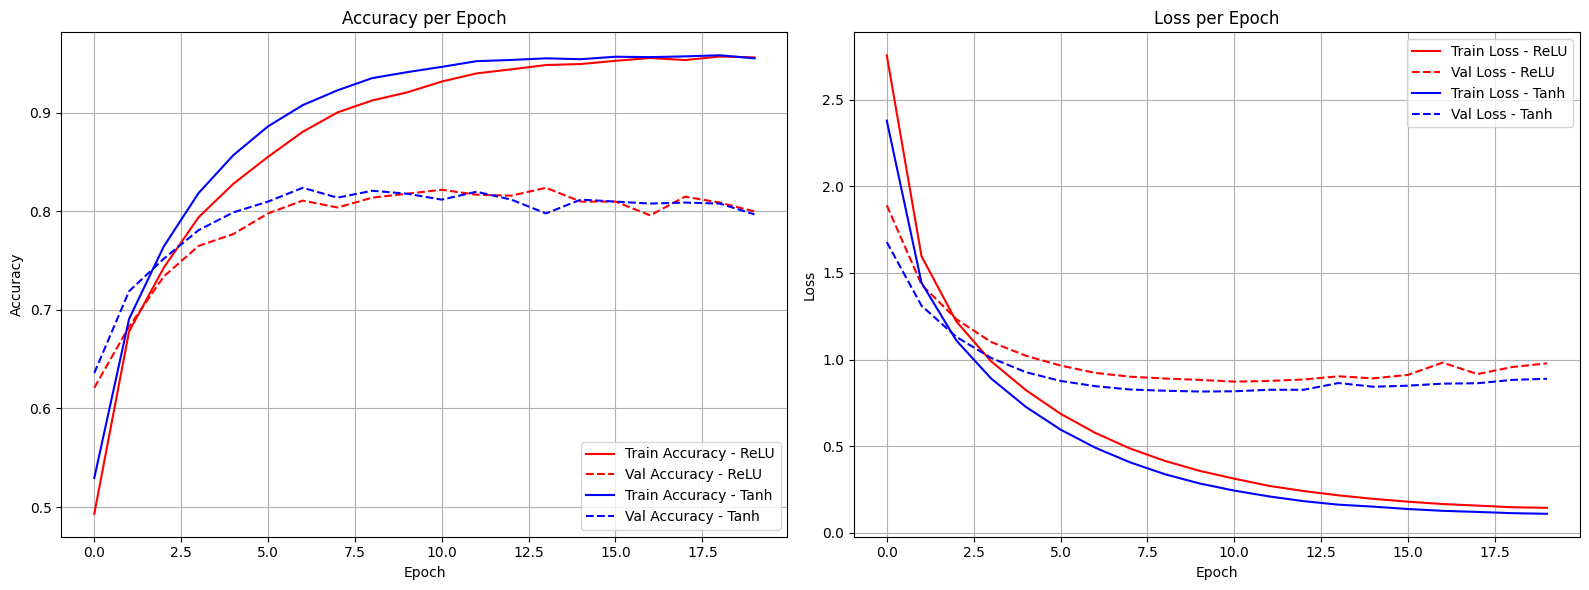

🔍 ReLU:
   Final Test Accuracy: 0.7872
   Final Test Loss: 1.0713

🔍 Tanh:
   Final Test Accuracy: 0.7885
   Final Test Loss: 1.0161


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from keras.datasets import reuters
from keras import models, layers
from keras.utils import to_categorical

# Load data
(train_data, train_labels), (test_data, test_labels) = reuters.load_data(num_words=10000)

# Vectorize sequences
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension), dtype='float32')
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.
    return results

x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)
y_train = to_categorical(train_labels)
y_test = to_categorical(test_labels)

# Split into training and validation
x_val = x_train[:1000]
partial_x_train = x_train[1000:]
y_val = y_train[:1000]
partial_y_train = y_train[1000:]

# Define function to build and train model
def build_and_train_model(activation_fn):
    model = models.Sequential()
    model.add(layers.Dense(64, activation=activation_fn, input_shape=(10000,)))
    model.add(layers.Dense(64, activation=activation_fn))
    model.add(layers.Dense(46, activation='softmax'))
    model.compile(optimizer='rmsprop',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    history = model.fit(partial_x_train, partial_y_train,
                        epochs=20, batch_size=512,
                        validation_data=(x_val, y_val), verbose=0)
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    return model, history, test_acc, test_loss

# Train both models
model_relu, history_relu, acc_relu, loss_relu = build_and_train_model('relu')
model_tanh, history_tanh, acc_tanh, loss_tanh = build_and_train_model('tanh')

# Plot accuracy and loss
plt.figure(figsize=(16, 6))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_relu.history['accuracy'], label='Train Accuracy - ReLU', color='red')
plt.plot(history_relu.history['val_accuracy'], label='Val Accuracy - ReLU', linestyle='--', color='red')
plt.plot(history_tanh.history['accuracy'], label='Train Accuracy - Tanh', color='blue')
plt.plot(history_tanh.history['val_accuracy'], label='Val Accuracy - Tanh', linestyle='--', color='blue')
plt.title('Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_relu.history['loss'], label='Train Loss - ReLU', color='red')
plt.plot(history_relu.history['val_loss'], label='Val Loss - ReLU', linestyle='--', color='red')
plt.plot(history_tanh.history['loss'], label='Train Loss - Tanh', color='blue')
plt.plot(history_tanh.history['val_loss'], label='Val Loss - Tanh', linestyle='--', color='blue')
plt.title('Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Print numerical results
print("🔍 ReLU:")
print(f"   Final Test Accuracy: {acc_relu:.4f}")
print(f"   Final Test Loss: {loss_relu:.4f}")

print("\n🔍 Tanh:")
print(f"   Final Test Accuracy: {acc_tanh:.4f}")
print(f"   Final Test Loss: {loss_tanh:.4f}")


MSE vs CrossEntropy

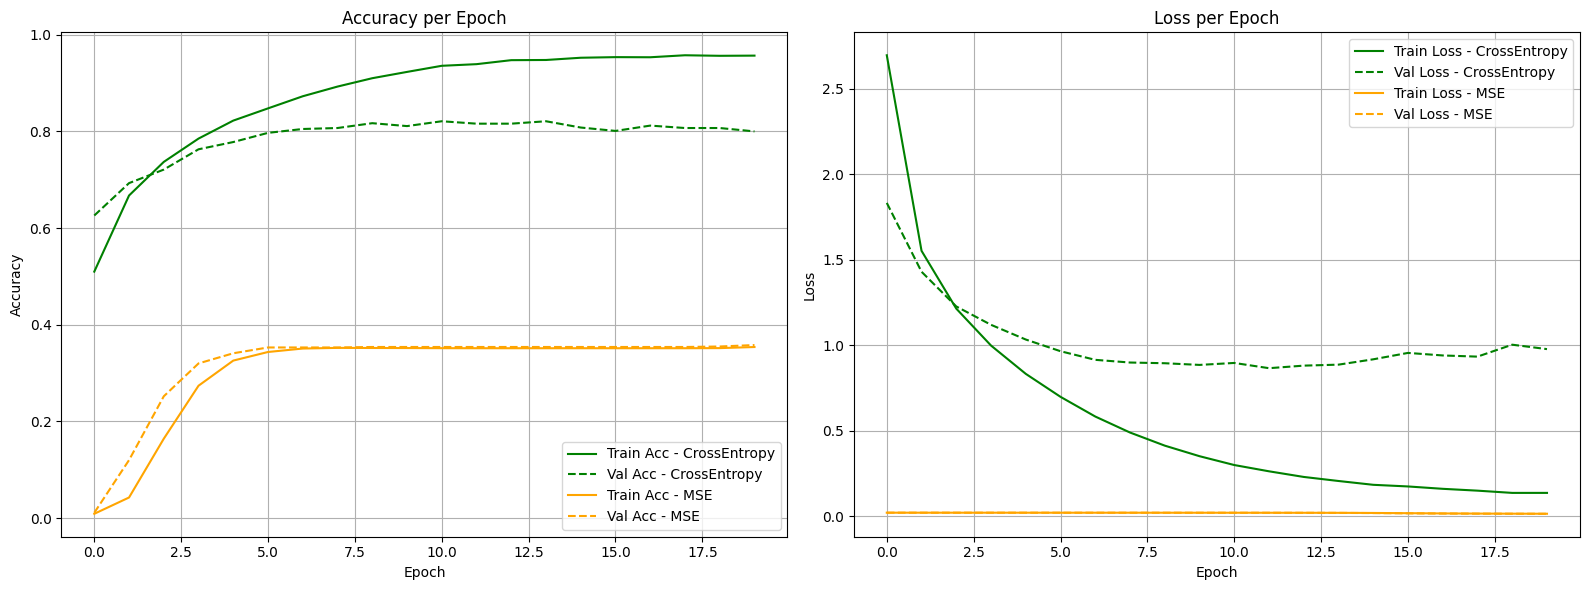

📘 CrossEntropy:
   Final Test Accuracy: 0.7841
   Final Test Loss: 1.0735

📙 MSE:
   Final Test Accuracy: 0.3709
   Final Test Loss: 0.0148


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from keras.datasets import reuters
from keras import models, layers
from keras.utils import to_categorical

# Load data
(train_data, train_labels), (test_data, test_labels) = reuters.load_data(num_words=10000)

# Vectorize sequences
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension), dtype='float32')
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.
    return results

x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)
y_train = to_categorical(train_labels)
y_test = to_categorical(test_labels)

# Split into training and validation
x_val = x_train[:1000]
partial_x_train = x_train[1000:]
y_val = y_train[:1000]
partial_y_train = y_train[1000:]

# تابع ساخت مدل با تابع خطا متفاوت
def build_and_train_model(loss_fn):
    model = models.Sequential()
    model.add(layers.Dense(64, activation='relu', input_shape=(10000,)))
    model.add(layers.Dense(64, activation='relu'))
    model.add(layers.Dense(46, activation='softmax'))
    model.compile(optimizer='rmsprop',
                  loss=loss_fn,
                  metrics=['accuracy'])
    history = model.fit(partial_x_train, partial_y_train,
                        epochs=20, batch_size=512,
                        validation_data=(x_val, y_val), verbose=0)
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    return model, history, test_acc, test_loss

# آموزش دو مدل با loss متفاوت
model_ce, history_ce, acc_ce, loss_ce = build_and_train_model('categorical_crossentropy')
model_mse, history_mse, acc_mse, loss_mse = build_and_train_model('mse')

# رسم نمودارها
plt.figure(figsize=(16, 6))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_ce.history['accuracy'], label='Train Acc - CrossEntropy', color='green')
plt.plot(history_ce.history['val_accuracy'], label='Val Acc - CrossEntropy', linestyle='--', color='green')
plt.plot(history_mse.history['accuracy'], label='Train Acc - MSE', color='orange')
plt.plot(history_mse.history['val_accuracy'], label='Val Acc - MSE', linestyle='--', color='orange')
plt.title('Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_ce.history['loss'], label='Train Loss - CrossEntropy', color='green')
plt.plot(history_ce.history['val_loss'], label='Val Loss - CrossEntropy', linestyle='--', color='green')
plt.plot(history_mse.history['loss'], label='Train Loss - MSE', color='orange')
plt.plot(history_mse.history['val_loss'], label='Val Loss - MSE', linestyle='--', color='orange')
plt.title('Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# نتایج عددی
print("📘 CrossEntropy:")
print(f"   Final Test Accuracy: {acc_ce:.4f}")
print(f"   Final Test Loss: {loss_ce:.4f}")

print("\n📙 MSE:")
print(f"   Final Test Accuracy: {acc_mse:.4f}")
print(f"   Final Test Loss: {loss_mse:.4f}")


تغییر تعداد کلمه ها

Training model with num_words = 1000...
Training model with num_words = 5000...
Training model with num_words = 10000...
Training model with num_words = 15000...


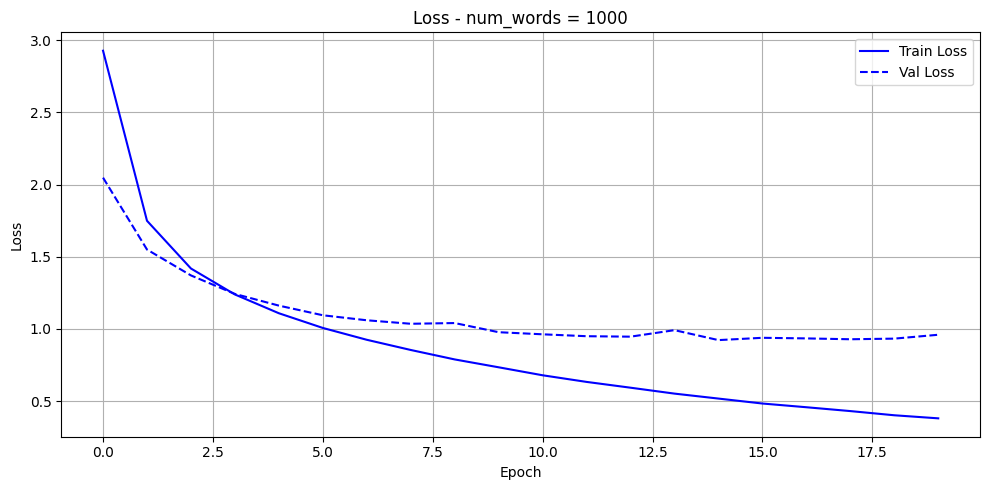

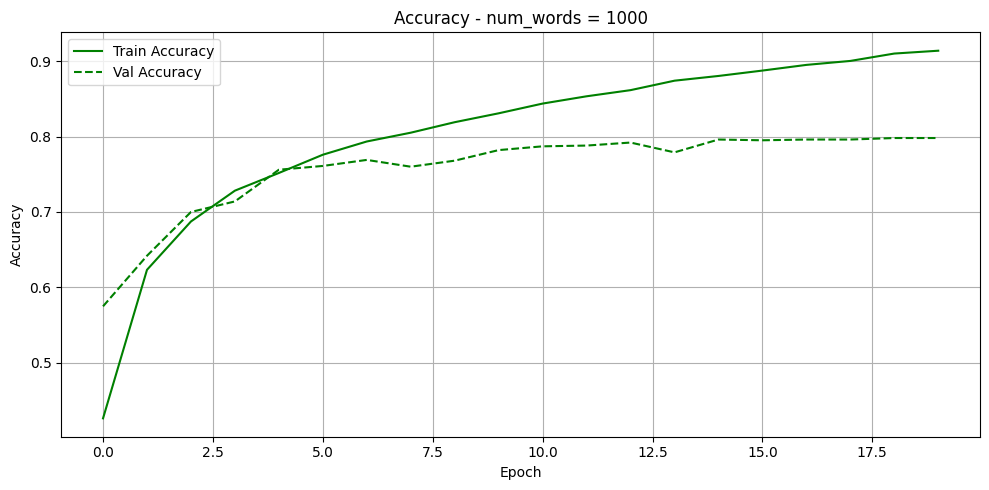

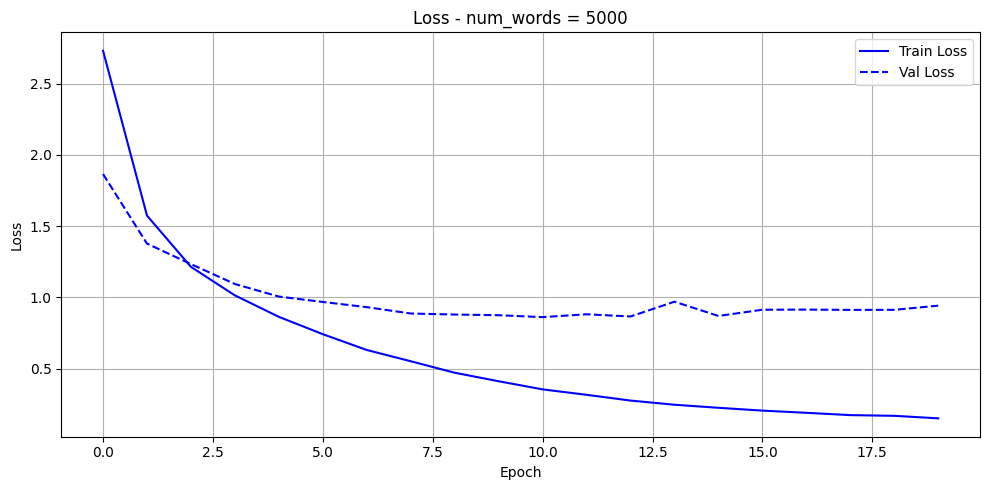

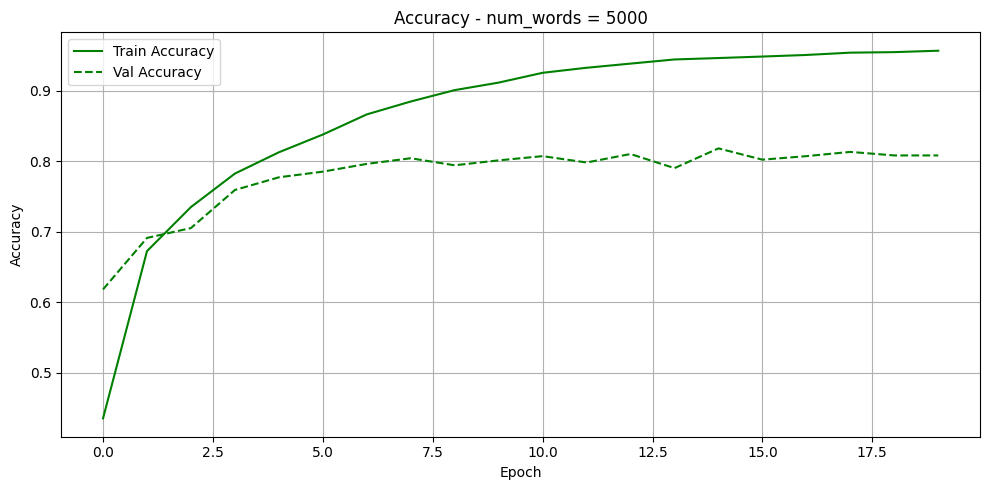

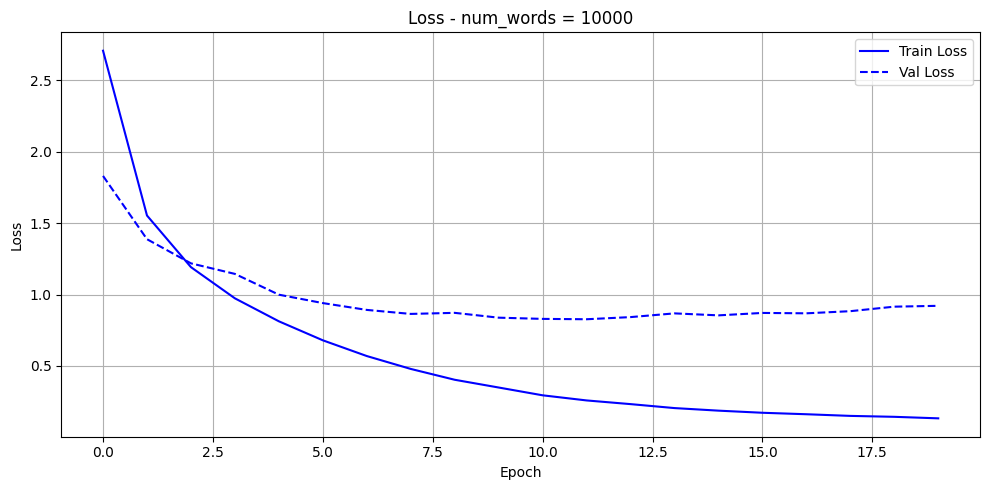

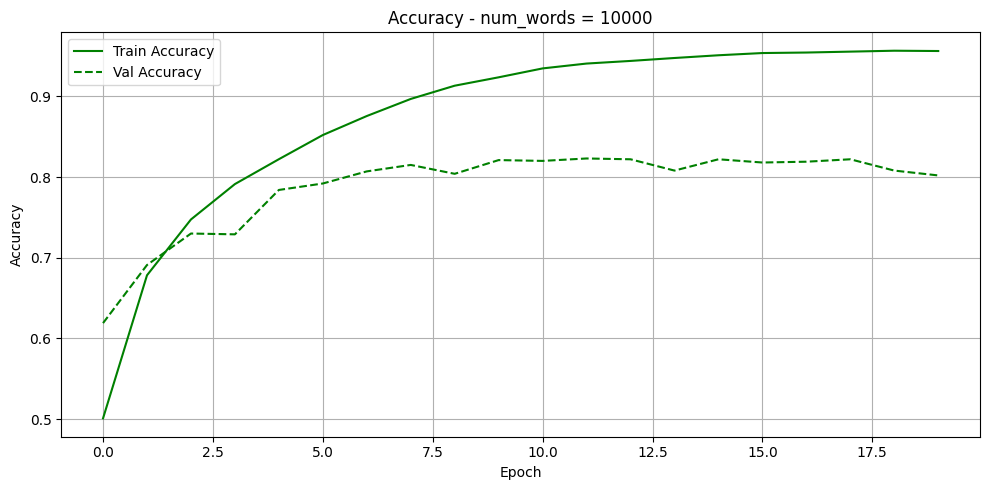

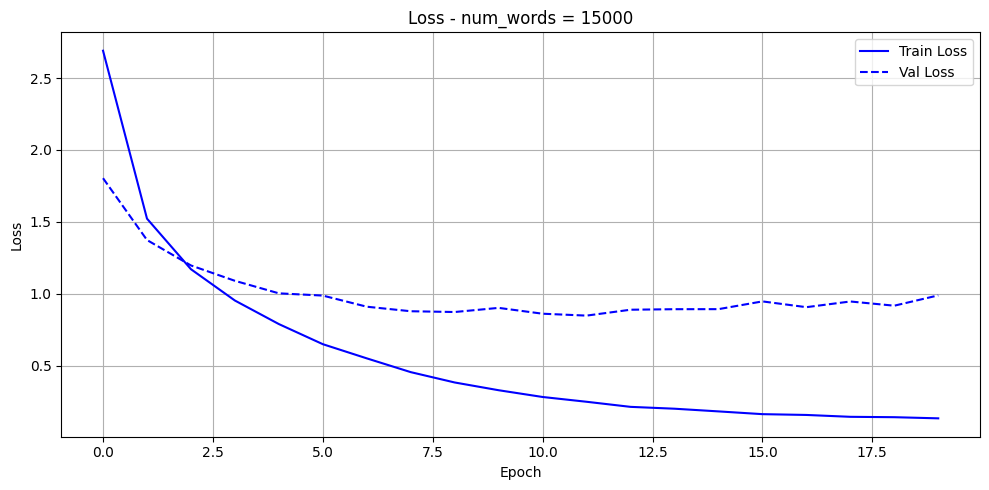

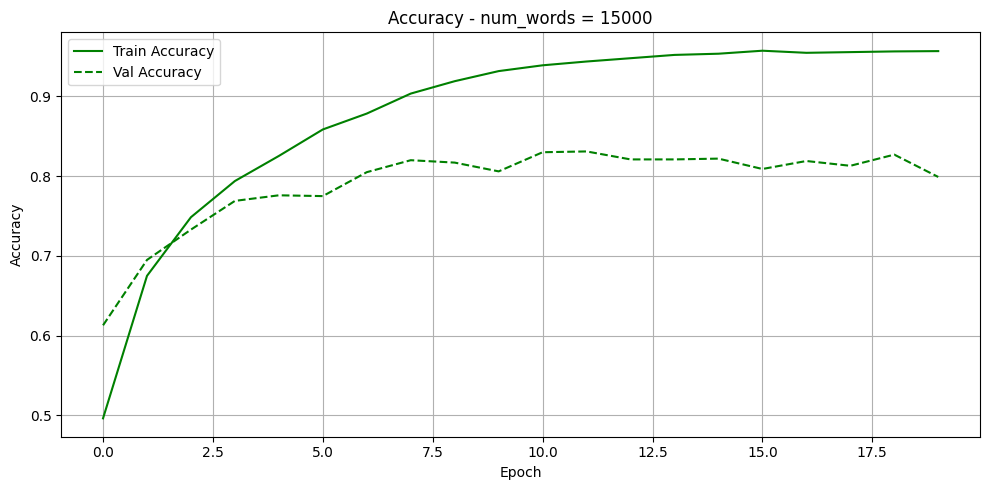

In [5]:
from keras.datasets import reuters
from keras import models, layers
from keras.utils import to_categorical
import numpy as np
import matplotlib.pyplot as plt

# تنظیمات مدل
num_words_list = [1000, 5000, 10000, 15000]
histories = {}

# آموزش مدل برای مقادیر مختلف num_words
for num_words in num_words_list:
    print(f"Training model with num_words = {num_words}...")
    
    (train_data, train_labels), (test_data, test_labels) = reuters.load_data(num_words=num_words)
    
    def vectorize_sequences(sequences, dimension=num_words):
        results = np.zeros((len(sequences), dimension))
        for i, sequence in enumerate(sequences):
            results[i, np.array(sequence)[np.array(sequence) < dimension]] = 1
        return results

    x_train = vectorize_sequences(train_data)
    x_test = vectorize_sequences(test_data)

    y_train = to_categorical(train_labels)
    y_test = to_categorical(test_labels)

    model = models.Sequential([
        layers.Dense(64, activation='relu', input_shape=(num_words,)),
        layers.Dense(64, activation='relu'),
        layers.Dense(46, activation='softmax')
    ])
    model.compile(optimizer='rmsprop', loss='categorical_crossentropy', metrics=['accuracy'])

    x_val = x_train[:1000]
    partial_x_train = x_train[1000:]
    y_val = y_train[:1000]
    partial_y_train = y_train[1000:]

    history = model.fit(partial_x_train, partial_y_train, epochs=20, batch_size=512, validation_data=(x_val, y_val), verbose=0)
    histories[num_words] = history

# رسم نمودار با استایل مشابه خواسته‌شده
linestyles = {
    'Train Loss': '-',
    'Val Loss': '--',
    'Train Accuracy': '-',
    'Val Accuracy': '--'
}

colors = {
    'Loss': 'blue',
    'Accuracy': 'green'
}

for num_words in num_words_list:
    history = histories[num_words].history

    # Loss
    plt.figure(figsize=(10, 5))
    plt.plot(history['loss'], label='Train Loss', color=colors['Loss'], linestyle=linestyles['Train Loss'])
    plt.plot(history['val_loss'], label='Val Loss', color=colors['Loss'], linestyle=linestyles['Val Loss'])
    plt.title(f"Loss - num_words = {num_words}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Accuracy
    plt.figure(figsize=(10, 5))
    plt.plot(history['accuracy'], label='Train Accuracy', color=colors['Accuracy'], linestyle=linestyles['Train Accuracy'])
    plt.plot(history['val_accuracy'], label='Val Accuracy', color=colors['Accuracy'], linestyle=linestyles['Val Accuracy'])
    plt.title(f"Accuracy - num_words = {num_words}")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


تغییر تعداد لایه ها

Training with 2 hidden layers...
Training with 5 hidden layers...
Training with 7 hidden layers...


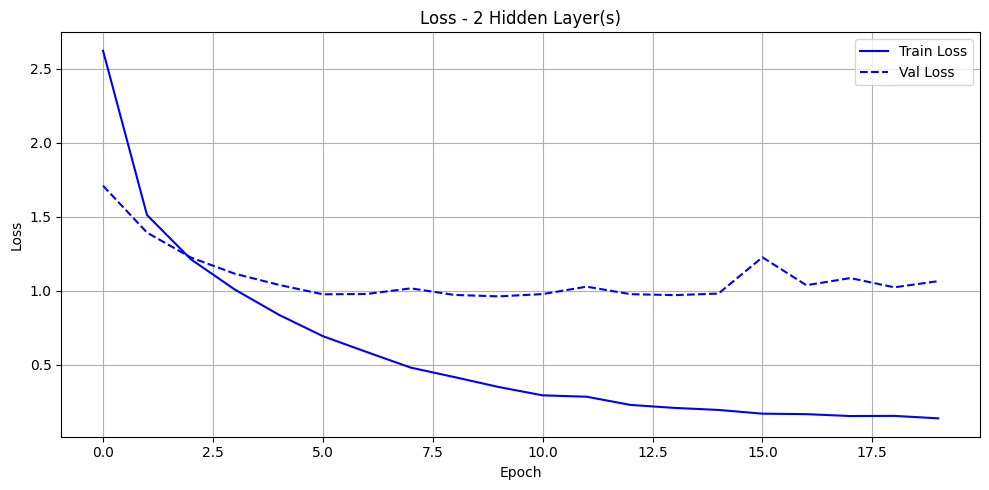

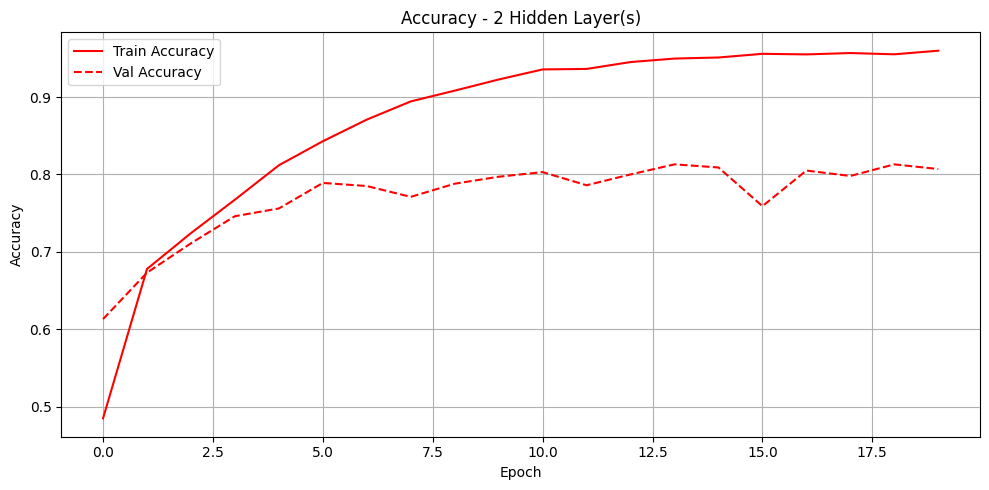

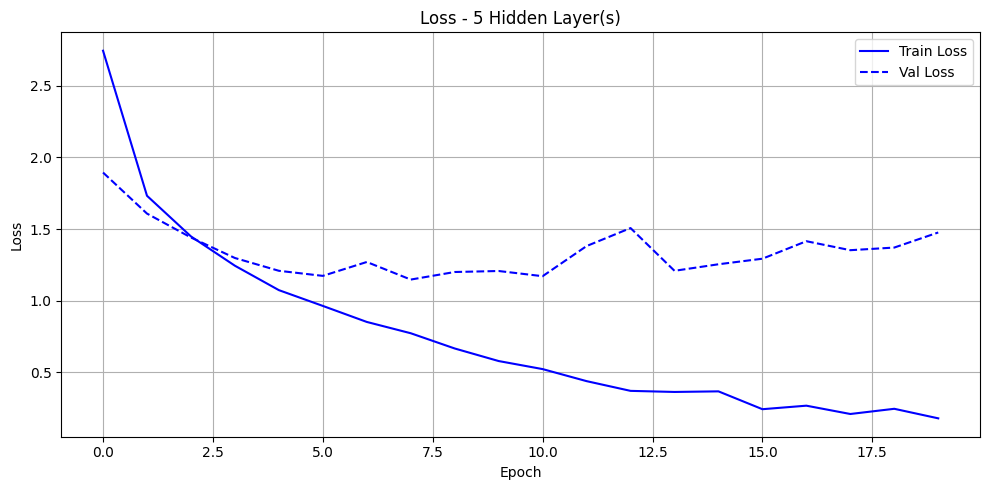

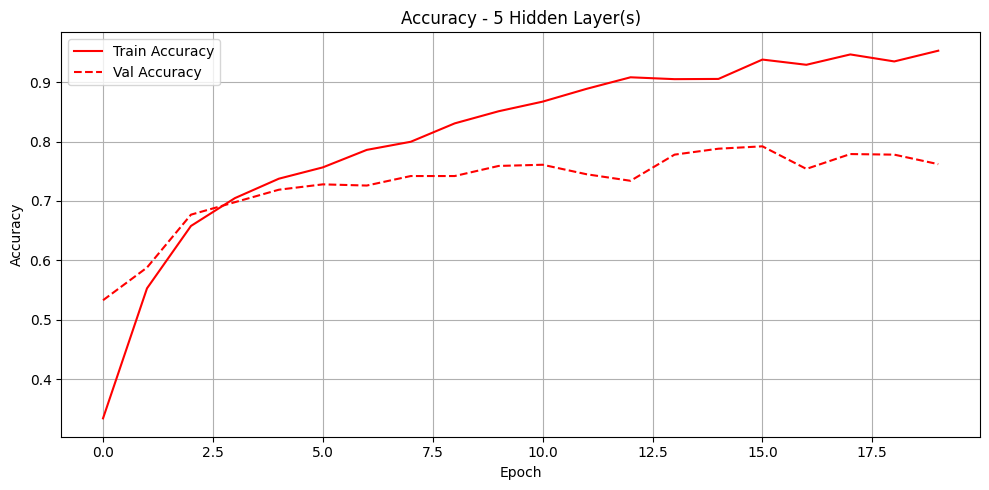

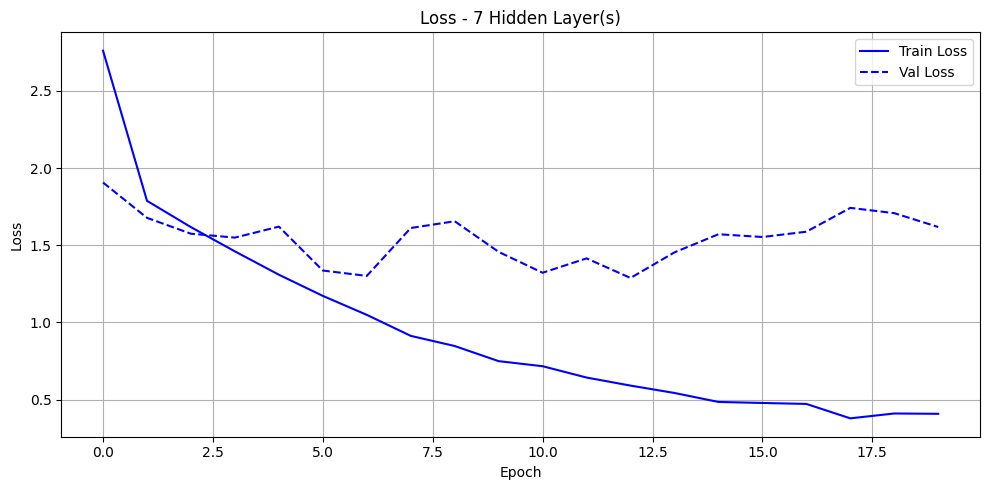

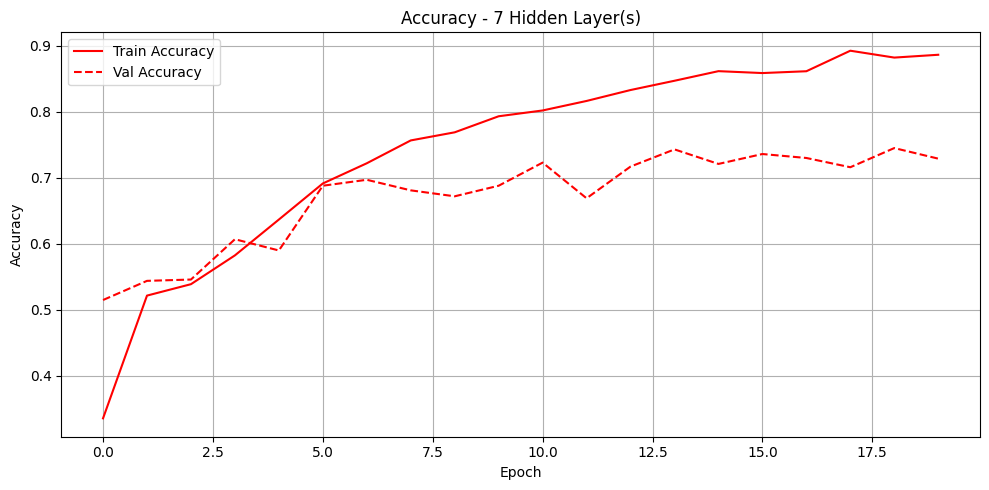

In [6]:
from keras.datasets import reuters
from keras import models, layers
from keras.utils import to_categorical
import numpy as np
import matplotlib.pyplot as plt

# Load Reuters dataset
(train_data, train_labels), (test_data, test_labels) = reuters.load_data(num_words=10000)

# Vectorize the sequences
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1
    return results

x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)

# Convert labels to one-hot encoding
one_hot_train_labels = to_categorical(train_labels)
one_hot_test_labels = to_categorical(test_labels)

# Split the data into training and validation sets
x_val = x_train[:1000]
partial_x_train = x_train[1000:]
y_val = one_hot_train_labels[:1000]
partial_y_train = one_hot_train_labels[1000:]

# Function to create and compile the model
def build_model(hidden_layers):
    model = models.Sequential()
    model.add(layers.Dense(64, activation='relu', input_shape=(10000,)))
    for _ in range(hidden_layers):
        model.add(layers.Dense(64, activation='relu'))
    model.add(layers.Dense(46, activation='softmax'))
    model.compile(optimizer='rmsprop', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Train and evaluate models with different number of hidden layers
hidden_layer_options = [2, 5, 7]
history_dict = {}

for hidden_layers in hidden_layer_options:
    print(f"Training with {hidden_layers} hidden layers...")
    model = build_model(hidden_layers)
    history = model.fit(partial_x_train, partial_y_train, epochs=20, batch_size=512, validation_data=(x_val, y_val), verbose=0)
    history_dict[hidden_layers] = history.history

# Plot the results
import matplotlib.pyplot as plt

linestyles = {
    'Train Loss': '-',
    'Val Loss': '--',
    'Train Accuracy': '-',
    'Val Accuracy': '--'
}

colors = {
    'Loss': 'blue',
    'Accuracy': 'red'
}

# نمایش نمودارها برای هر تعداد لایه
for hidden_layers in hidden_layer_options:
    history = history_dict[hidden_layers]
    
    # نمودار Loss
    plt.figure(figsize=(10, 5))
    plt.plot(history['loss'], label='Train Loss', color=colors['Loss'], linestyle=linestyles['Train Loss'])
    plt.plot(history['val_loss'], label='Val Loss', color=colors['Loss'], linestyle=linestyles['Val Loss'])
    plt.title(f"Loss - {hidden_layers} Hidden Layer(s)")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # نمودار Accuracy
    plt.figure(figsize=(10, 5))
    plt.plot(history['accuracy'], label='Train Accuracy', color=colors['Accuracy'], linestyle=linestyles['Train Accuracy'])
    plt.plot(history['val_accuracy'], label='Val Accuracy', color=colors['Accuracy'], linestyle=linestyles['Val Accuracy'])
    plt.title(f"Accuracy - {hidden_layers} Hidden Layer(s)")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


تغییر تعداد نورون ها

Training with 32 neurons...
Training with 64 neurons...
Training with 128 neurons...
Training with 256 neurons...


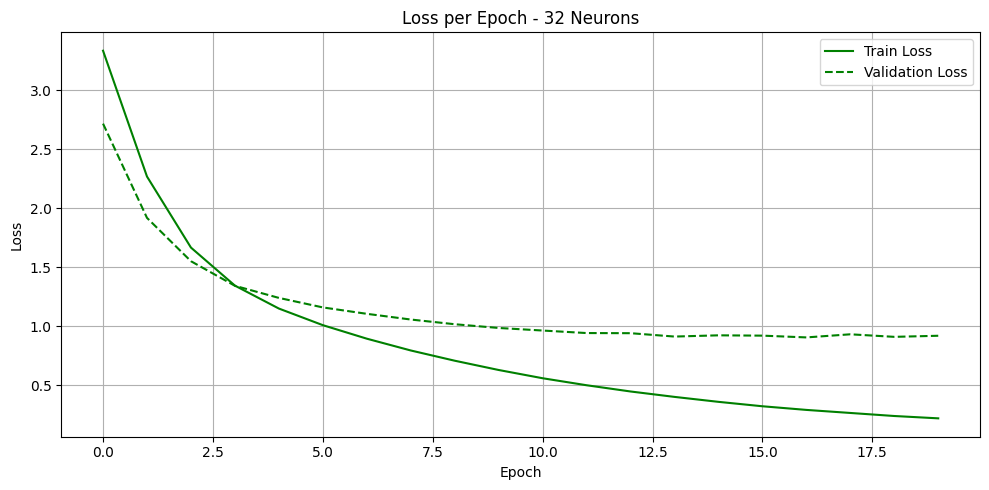

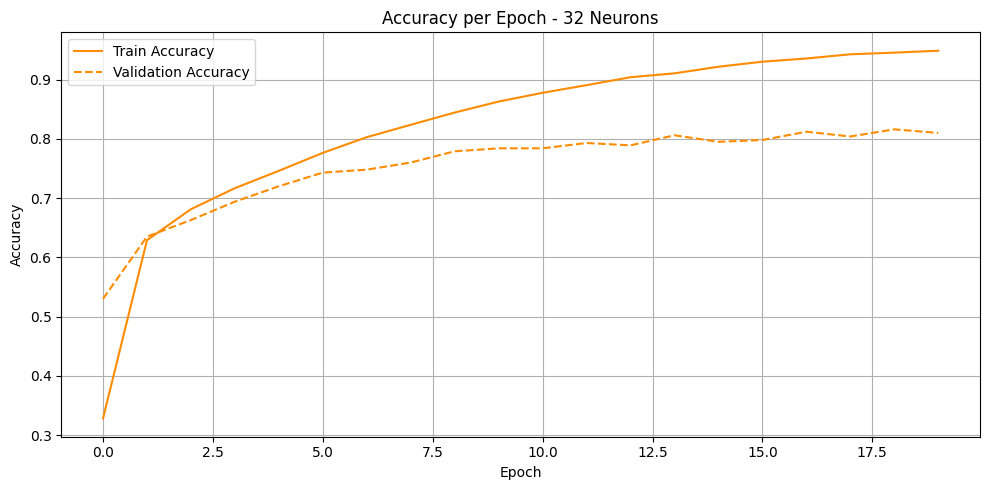

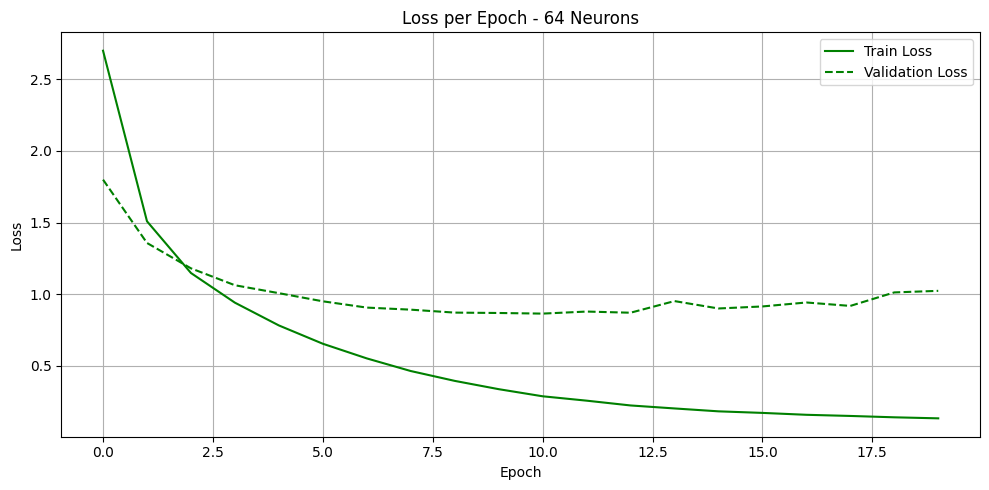

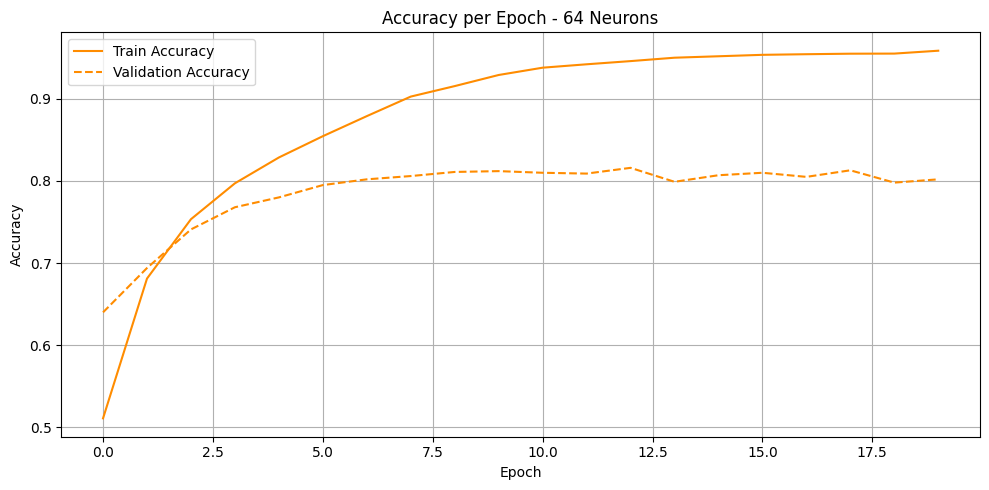

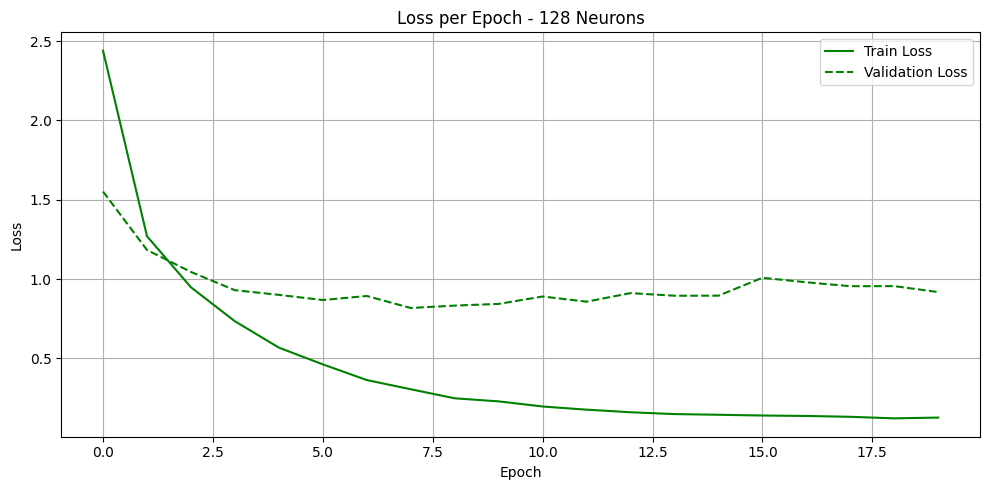

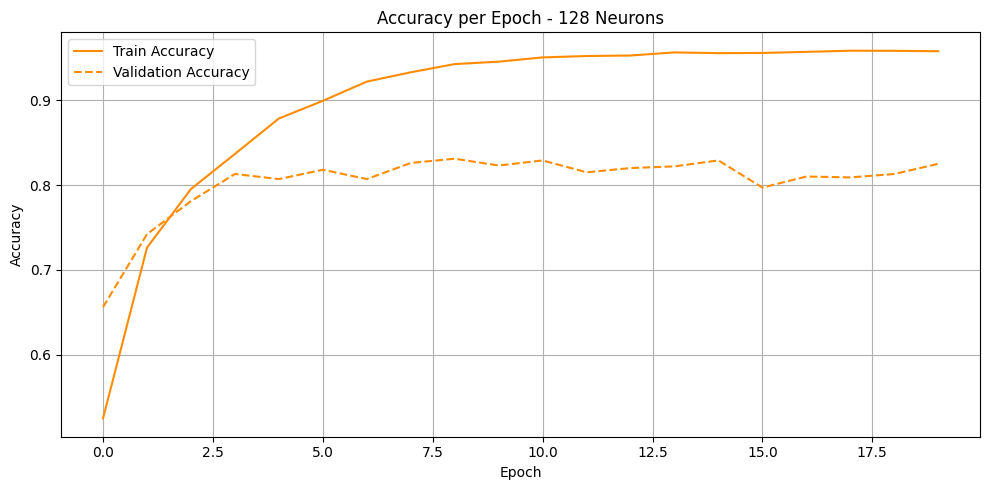

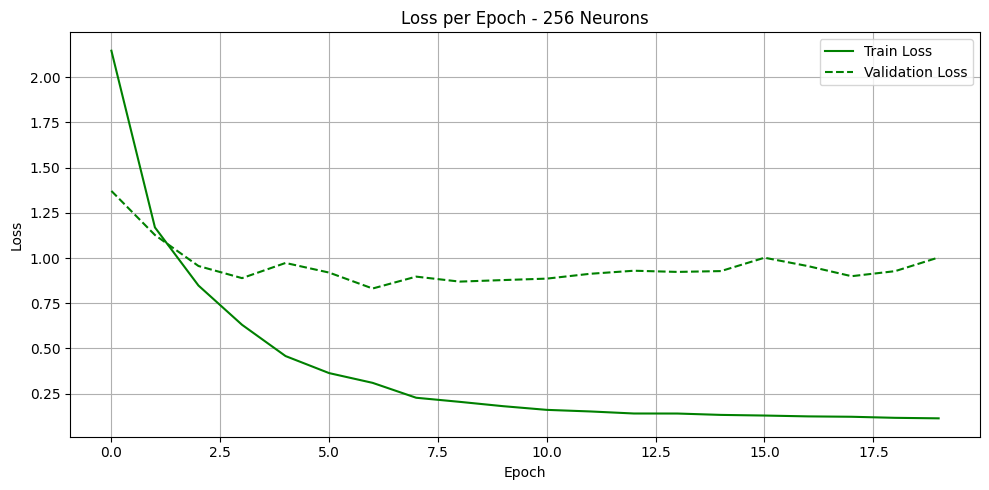

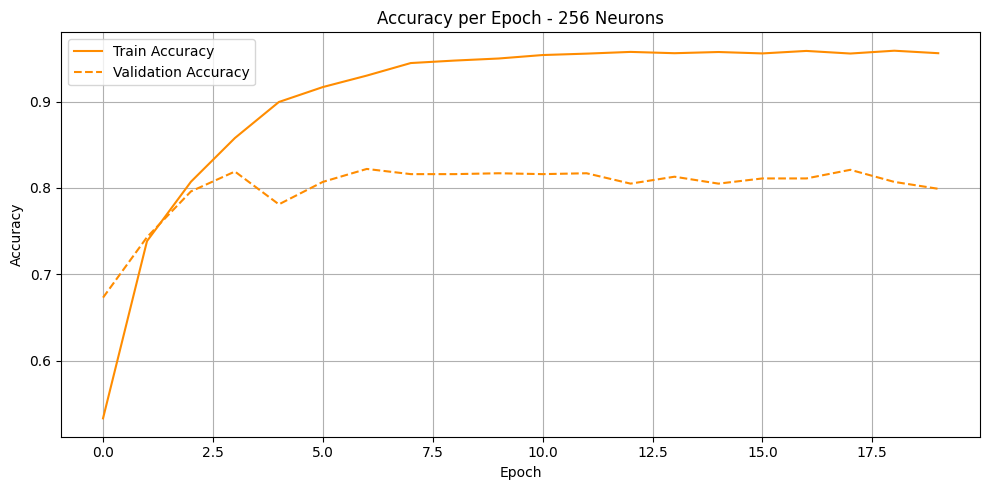

In [10]:
from keras.datasets import reuters
from keras import models, layers
from keras.utils import to_categorical
import numpy as np
import matplotlib.pyplot as plt

# Load Reuters dataset
(train_data, train_labels), (test_data, test_labels) = reuters.load_data(num_words=10000)

# Vectorize the sequences
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1
    return results

x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)

# Convert labels to one-hot encoding
one_hot_train_labels = to_categorical(train_labels)
one_hot_test_labels = to_categorical(test_labels)

# Split the data into training and validation sets
x_val = x_train[:1000]
partial_x_train = x_train[1000:]
y_val = one_hot_train_labels[:1000]
partial_y_train = one_hot_train_labels[1000:]

# Function to create and compile the model
def build_model(neurons):
    model = models.Sequential()
    model.add(layers.Dense(neurons, activation='relu', input_shape=(10000,)))
    model.add(layers.Dense(neurons, activation='relu'))
    model.add(layers.Dense(46, activation='softmax'))
    model.compile(optimizer='rmsprop', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Train and evaluate models with different numbers of neurons in the first hidden layer
neurons_options = [32, 64, 128, 256]
history_dict = {}

for neurons in neurons_options:
    print(f"Training with {neurons} neurons...")
    model = build_model(neurons)
    history = model.fit(partial_x_train, partial_y_train, epochs=20, batch_size=512, validation_data=(x_val, y_val), verbose=0)
    history_dict[neurons] = history.history

# Plot the results
for neurons in neurons_options:
    history = history_dict[neurons]

    # نمودار Loss
    plt.figure(figsize=(10, 5))
    plt.plot(history['loss'], label='Train Loss', linestyle='-',color="green")
    plt.plot(history['val_loss'], label='Validation Loss', linestyle='--',color="green")
    plt.title(f"Loss per Epoch - {neurons} Neurons")
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # نمودار Accuracy
    plt.figure(figsize=(10, 5))
    plt.plot(history['accuracy'], label='Train Accuracy', linestyle='-',color="darkorange")
    plt.plot(history['val_accuracy'], label='Validation Accuracy', linestyle='--',color="darkorange")
    plt.title(f"Accuracy per Epoch - {neurons} Neurons")
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
